In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

sns.set_theme(style="whitegrid")

df = pd.read_csv("sales_data.csv")
df.head()

,Date,Store ID,Product ID,Category,Region,Inventory Level,Units Sold,Units Ordered,Price,Discount,Weather Condition,Promotion,Competitor Pricing,Seasonality,Epidemic,Demand
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,5,Snowy,0,85.73,Winter,0,115
1,2022-01-01,S001,P0002,Clothing,North,117,117,249,80.16,15,Snowy,1,92.02,Winter,0,229
2,2022-01-01,S001,P0003,Clothing,North,247,114,612,62.94,10,Snowy,1,60.08,Winter,0,157
3,2022-01-01,S001,P0004,Electronics,North,139,45,102,87.63,10,Snowy,0,85.19,Winter,0,52
4,2022-01-01,S001,P0005,Groceries,North,152,65,271,54.41,0,Snowy,0,51.63,Winter,0,59


In [2]:
df.columns = df.columns.str.lower().str.replace(" ", "_")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 76000 entries, 0 to 75999
Data columns (total 16 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   date                76000 non-null  str    
 1   store_id            76000 non-null  str    
 2   product_id          76000 non-null  str    
 3   category            76000 non-null  str    
 4   region              76000 non-null  str    
 5   inventory_level     76000 non-null  int64  
 6   units_sold          76000 non-null  int64  
 7   units_ordered       76000 non-null  int64  
 8   price               76000 non-null  float64
 9   discount            76000 non-null  int64  
 10  weather_condition   76000 non-null  str    
 11  promotion           76000 non-null  int64  
 12  competitor_pricing  76000 non-null  float64
 13  seasonality         76000 non-null  str    
 14  epidemic            76000 non-null  int64  
 15  demand              76000 non-null  int64  
dtypes: float64(2), 

In [3]:
df.describe().round(2)

,inventory_level,units_sold,units_ordered,price,discount,promotion,competitor_pricing,epidemic,demand
count,76000.00,76000.00,76000.00,76000.00,76000.00,76000.00,76000.00,76000.0,76000.00
mean,301.06,88.83,89.09,67.73,9.09,0.33,69.45,0.2,104.32
std,226.51,43.99,162.40,39.38,7.48,0.47,40.94,0.4,46.96
min,0.00,0.00,0.00,4.74,0.00,0.00,4.29,0.0,4.00
25%,136.00,58.00,0.00,32.00,5.00,0.00,32.62,0.0,71.00
50%,227.00,84.00,0.00,64.50,10.00,0.00,65.70,0.0,100.00
75%,408.00,114.00,121.00,95.83,10.00,1.00,97.93,0.0,133.00
max,2267.00,426.00,1616.00,228.03,25.00,1.00,261.22,1.0,430.00


In [4]:
print("Missing values per column:")
print(df.isnull().sum())
print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values per column:
date                  0
store_id              0
product_id            0
category              0
region                0
inventory_level       0
units_sold            0
units_ordered         0
price                 0
discount              0
weather_condition     0
promotion             0
competitor_pricing    0
seasonality           0
epidemic              0
demand                0
dtype: int64
Total missing values: 0
Duplicate rows: 0


In [5]:
rows_before = len(df)
df = df.dropna().drop_duplicates().copy()
print("Rows removed:", rows_before - len(df))

df["date"] = pd.to_datetime(df["date"])
df["revenue"] = df["units_sold"] * df["price"] * (1 - df["discount"] / 100)
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["year_month"] = df["date"].dt.to_period("M").astype(str)

print("Shape:", df.shape)
print("Date range:", df["date"].min().date(), "to", df["date"].max().date())

Rows removed: 0
Shape: (76000, 20)
Date range: 2022-01-01 to 2024-01-30


In [6]:
cols = ["units_sold", "demand", "price", "inventory_level"]

for c in cols:
    q1 = df[c].quantile(0.25)
    q3 = df[c].quantile(0.75)
    iqr = q3 - q1
    low = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    n = ((df[c] < low) | (df[c] > high)).sum()
    print(f"{c:16s} outliers = {n:5d} ({n / len(df):.1%})")

units_sold       outliers =  1411 (1.9%)
demand           outliers =   986 (1.3%)
price            outliers =    70 (0.1%)
inventory_level  outliers =  2759 (3.6%)


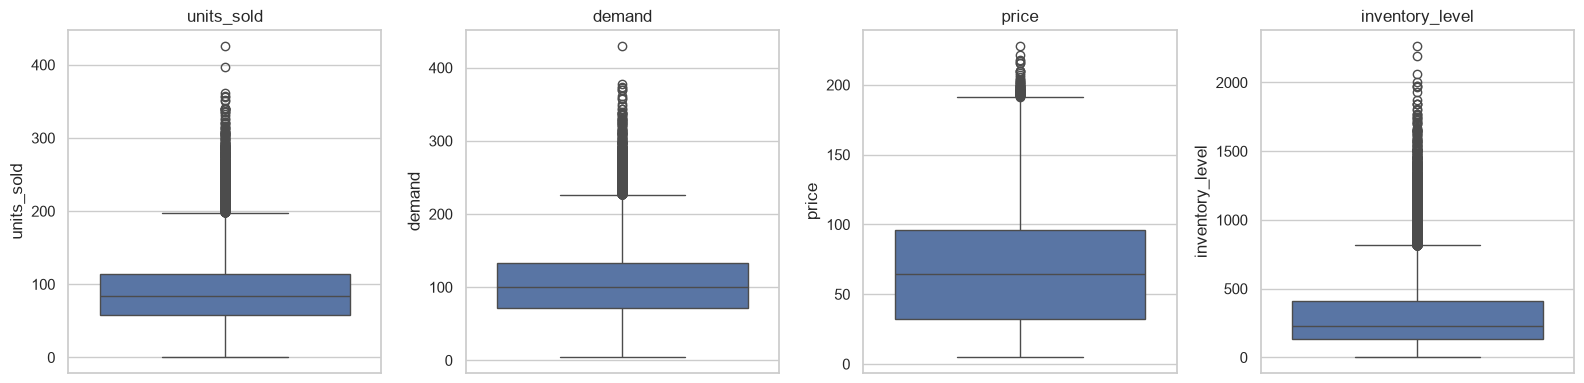

In [7]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, c in zip(axes, cols):
    sns.boxplot(y=df[c], ax=ax)
    ax.set_title(c)
plt.tight_layout()
plt.show()

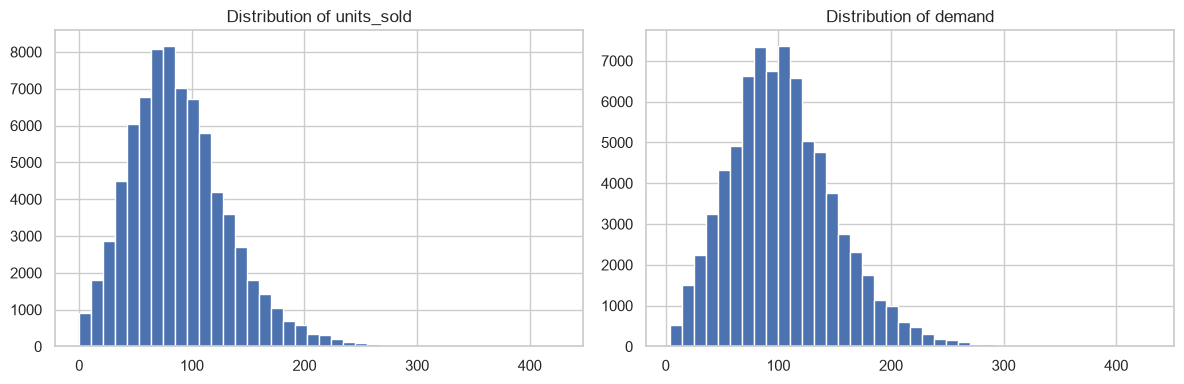

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df["units_sold"], bins=40)
axes[0].set_title("Distribution of units_sold")

axes[1].hist(df["demand"], bins=40)
axes[1].set_title("Distribution of demand")

plt.tight_layout()
plt.show()

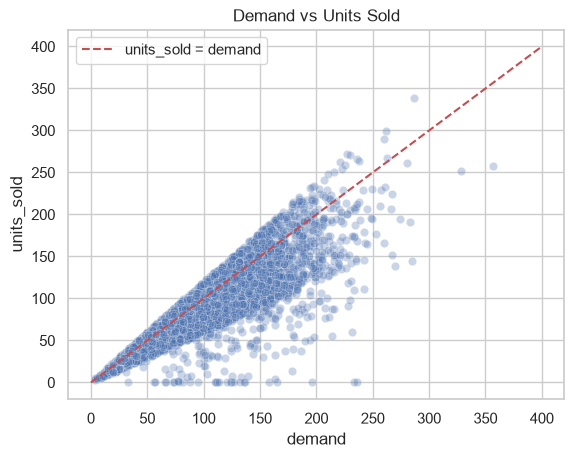

In [9]:
sample = df.sample(5000, random_state=42)

sns.scatterplot(data=sample, x="demand", y="units_sold", alpha=0.3)
plt.plot([0, 400], [0, 400], "r--", label="units_sold = demand")
plt.legend()
plt.title("Demand vs Units Sold")
plt.show()

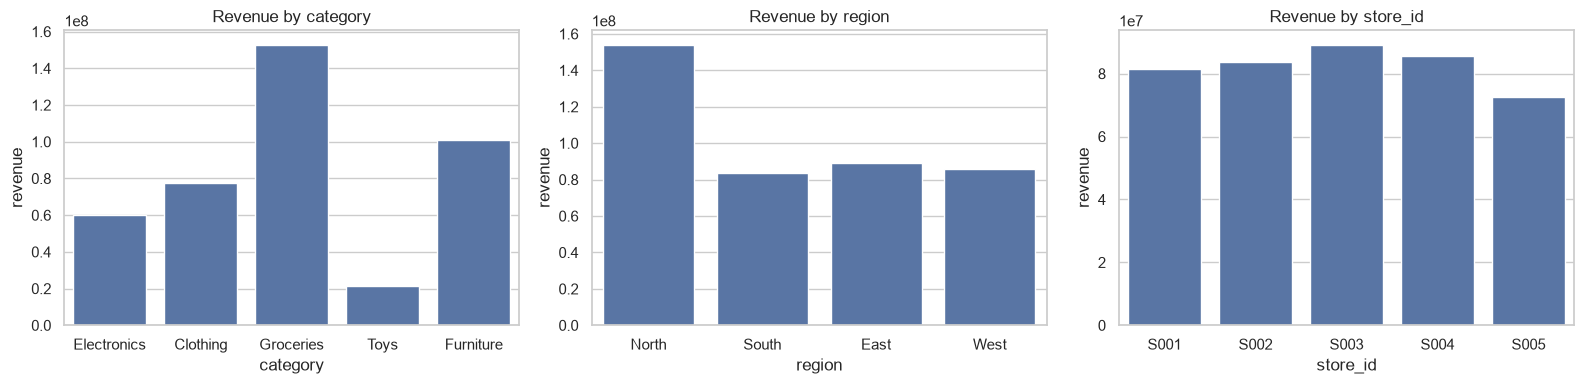

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, col in zip(axes, ["category", "region", "store_id"]):
    sns.barplot(data=df, x=col, y="revenue", estimator="sum", errorbar=None, ax=ax)
    ax.set_title("Revenue by " + col)

plt.tight_layout()
plt.show()

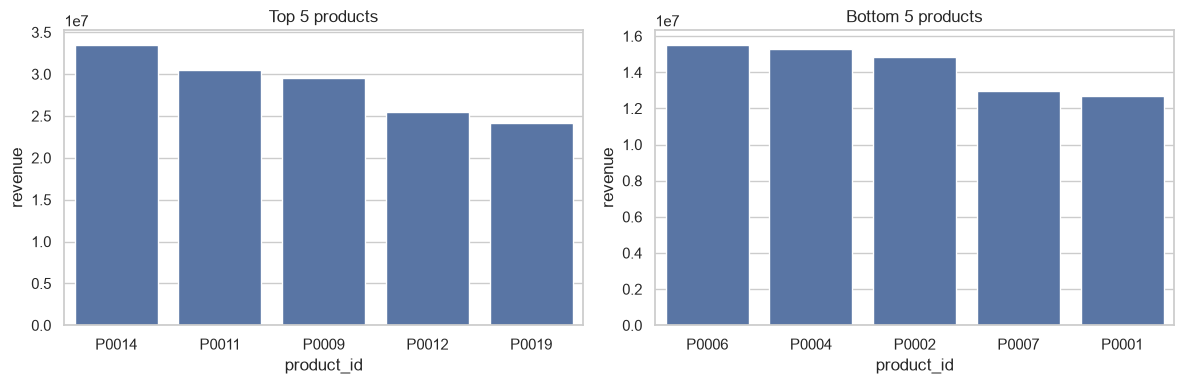

In [11]:
products = df.groupby("product_id")["revenue"].sum().sort_values(ascending=False).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=products.head(5), x="product_id", y="revenue", ax=axes[0])
axes[0].set_title("Top 5 products")
sns.barplot(data=products.tail(5), x="product_id", y="revenue", ax=axes[1])
axes[1].set_title("Bottom 5 products")

plt.tight_layout()
plt.show()

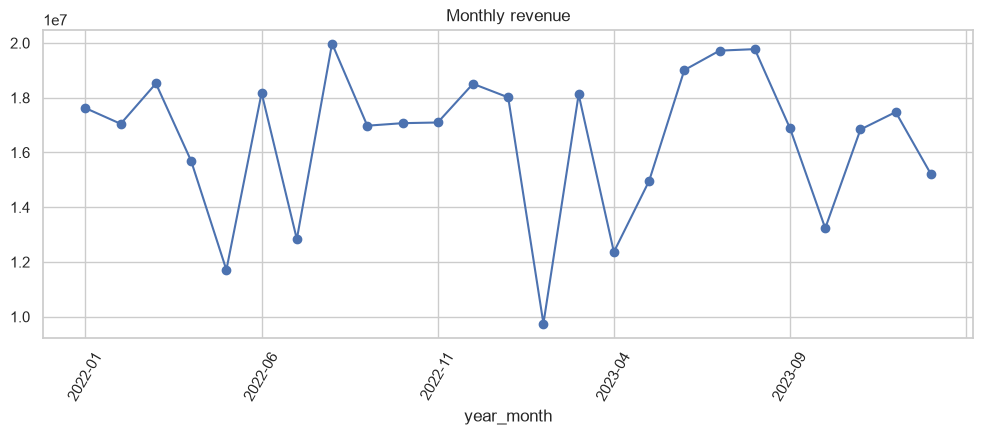

In [12]:
monthly = df.groupby("year_month")["revenue"].sum()

monthly.plot(marker="o", figsize=(12, 4), title="Monthly revenue")
plt.xticks(rotation=60)
plt.show()

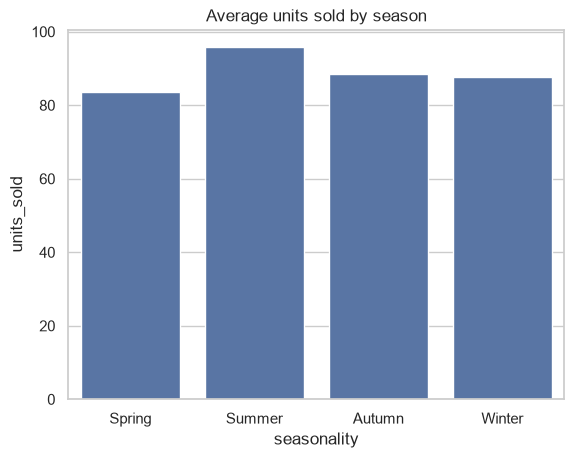

In [13]:
sns.barplot(data=df, x="seasonality", y="units_sold", errorbar=None,
            order=["Spring", "Summer", "Autumn", "Winter"])
plt.title("Average units sold by season")
plt.show()

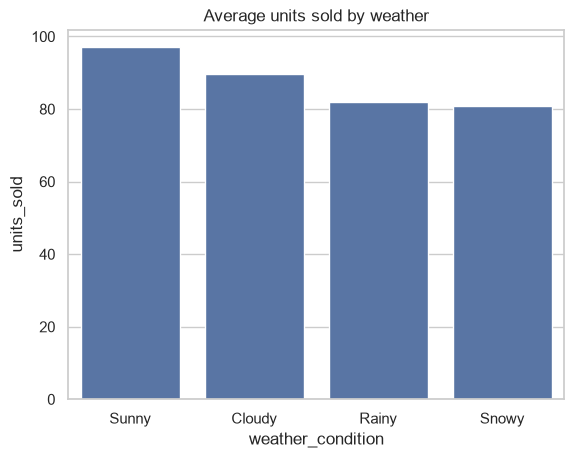

In [14]:
sns.barplot(data=df, x="weather_condition", y="units_sold", errorbar=None,
            order=["Sunny", "Cloudy", "Rainy", "Snowy"])
plt.title("Average units sold by weather")
plt.show()

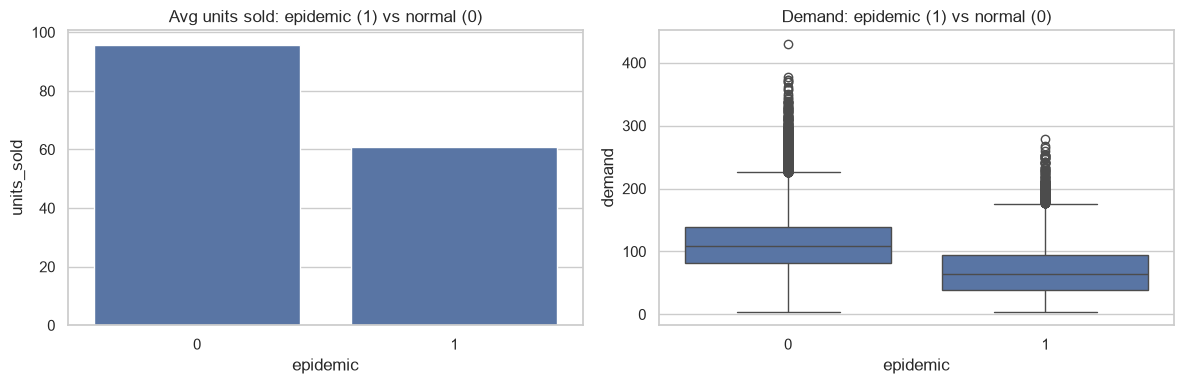

          units_sold  demand
epidemic                    
0               95.8   112.9
1               60.9    70.2


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(data=df, x="epidemic", y="units_sold", errorbar=None, ax=axes[0])
axes[0].set_title("Avg units sold: epidemic (1) vs normal (0)")

sns.boxplot(data=df, x="epidemic", y="demand", ax=axes[1])
axes[1].set_title("Demand: epidemic (1) vs normal (0)")

plt.tight_layout()
plt.show()

print(df.groupby("epidemic")[["units_sold", "demand"]].mean().round(1))

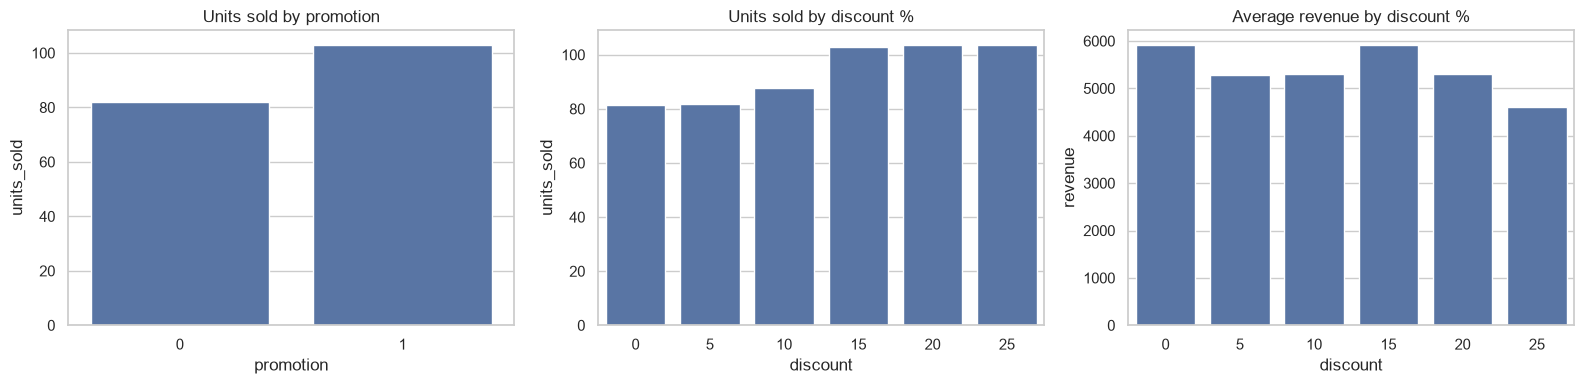

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

sns.barplot(data=df, x="promotion", y="units_sold", errorbar=None, ax=axes[0])
axes[0].set_title("Units sold by promotion")

sns.barplot(data=df, x="discount", y="units_sold", errorbar=None, ax=axes[1])
axes[1].set_title("Units sold by discount %")

sns.barplot(data=df, x="discount", y="revenue", errorbar=None, ax=axes[2])
axes[2].set_title("Average revenue by discount %")

plt.tight_layout()
plt.show()

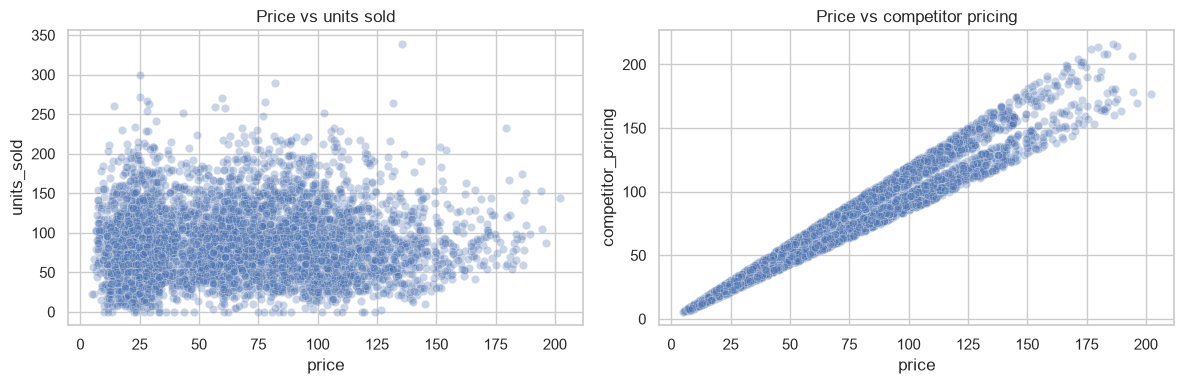

In [17]:
sample = df.sample(5000, random_state=42)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.scatterplot(data=sample, x="price", y="units_sold", alpha=0.3, ax=axes[0])
axes[0].set_title("Price vs units sold")

sns.scatterplot(data=sample, x="price", y="competitor_pricing", alpha=0.3, ax=axes[1])
axes[1].set_title("Price vs competitor pricing")

plt.tight_layout()
plt.show()

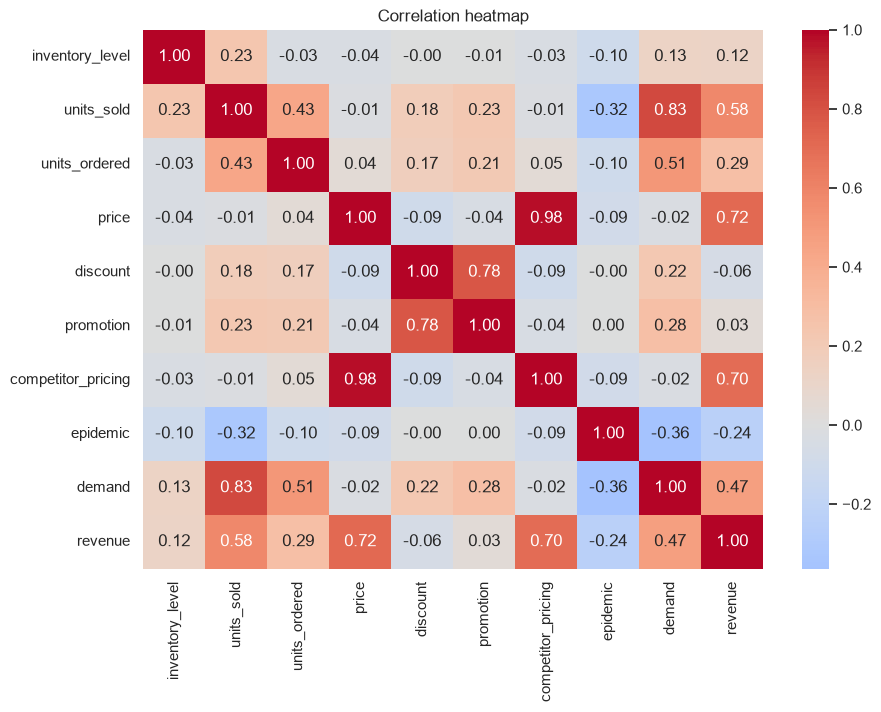

In [18]:
numeric = df.select_dtypes(include="number").drop(columns=["year", "month"])

plt.figure(figsize=(10, 7))
sns.heatmap(numeric.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.show()

In [19]:
conn = sqlite3.connect("retail_sales.db")

sales = df.copy()
sales["date"] = sales["date"].dt.strftime("%Y-%m-%d")
sales.to_sql("sales", conn, if_exists="replace", index=False)

def q(sql):
    return pd.read_sql_query(sql, conn)

q("SELECT * FROM sales LIMIT 5")

,date,store_id,product_id,category,region,inventory_level,units_sold,units_ordered,price,discount,weather_condition,promotion,competitor_pricing,seasonality,epidemic,demand,revenue,year,month,year_month
0,2022-01-01,S001,P0001,Electronics,North,195,102,252,72.72,5,Snowy,0,85.73,Winter,0,115,7046.568,2022,1,2022-01
1,2022-01-01,S001,P0002,Clothing,North,117,117,249,80.16,15,Snowy,1,92.02,Winter,0,229,7971.912,2022,1,2022-01
2,2022-01-01,S001,P0003,Clothing,North,247,114,612,62.94,10,Snowy,1,60.08,Winter,0,157,6457.644,2022,1,2022-01
3,2022-01-01,S001,P0004,Electronics,North,139,45,102,87.63,10,Snowy,0,85.19,Winter,0,52,3549.015,2022,1,2022-01
4,2022-01-01,S001,P0005,Groceries,North,152,65,271,54.41,0,Snowy,0,51.63,Winter,0,59,3536.650,2022,1,2022-01


In [20]:
q("""
SELECT SUM(revenue)    AS total_revenue,
       SUM(units_sold) AS total_units,
       AVG(price)      AS avg_price,
       COUNT(*)        AS total_rows
FROM sales
""")

,total_revenue,total_units,avg_price,total_rows
0,4.125906e+08,6750876,67.726028,76000


In [21]:
def sales_by(column):
    return q(f"""
    SELECT {column},
           SUM(revenue)    AS revenue,
           SUM(units_sold) AS units_sold
    FROM sales
    GROUP BY {column}
    ORDER BY revenue DESC
    """)

sales_by("category")

,category,revenue,units_sold
0,Groceries,1.529578e+08,3127335
1,Furniture,1.008930e+08,880654
2,Clothing,7.725332e+07,1150873
3,Electronics,5.983031e+07,757335
4,Toys,2.165611e+07,834679


In [22]:
sales_by("region")

,region,revenue,units_sold
0,North,1.541444e+08,2680946
1,East,8.925563e+07,1375613
2,West,8.559825e+07,1308191
3,South,8.359233e+07,1386126


In [23]:
sales_by("store_id")

,store_id,revenue,units_sold
0,S003,8.925563e+07,1375613
1,S004,8.559825e+07,1308191
2,S002,8.359233e+07,1386126
3,S001,8.155536e+07,1318134
4,S005,7.258902e+07,1362812


In [24]:
sales_by("product_id").head(10)

,product_id,revenue,units_sold
0,P0014,3.353957e+07,317397
1,P0011,3.044271e+07,332883
2,P0009,2.952064e+07,376771
3,P0012,2.547118e+07,296256
4,P0019,2.411346e+07,313209
5,P0003,2.383988e+07,341531
6,P0020,2.280406e+07,277961
7,P0016,2.162936e+07,326718
8,P0010,2.088146e+07,357299
9,P0015,2.047609e+07,335443


In [25]:
sales_by("year_month").sort_values("year_month")

,year_month,revenue,units_sold
9,2022-01,1.762094e+07,283495
13,2022-02,1.704631e+07,271108
4,2022-03,1.852041e+07,303752
17,2022-04,1.569041e+07,260812
23,2022-05,1.171124e+07,205949
6,2022-06,1.817486e+07,292816
21,2022-07,1.283427e+07,220157
0,2022-08,1.997949e+07,316705
14,2022-09,1.697838e+07,277151
12,2022-10,1.707049e+07,280227


In [26]:
q("""
SELECT product_id, SUM(revenue) AS revenue
FROM sales
GROUP BY product_id
ORDER BY revenue DESC
LIMIT 5
""")

,product_id,revenue
0,P0014,3.353957e+07
1,P0011,3.044271e+07
2,P0009,2.952064e+07
3,P0012,2.547118e+07
4,P0019,2.411346e+07


In [27]:
q("""
SELECT product_id, SUM(revenue) AS revenue
FROM sales
GROUP BY product_id
ORDER BY revenue ASC
LIMIT 5
""")

,product_id,revenue
0,P0001,1.267224e+07
1,P0007,1.297319e+07
2,P0002,1.485310e+07
3,P0004,1.530041e+07
4,P0006,1.553627e+07


In [28]:
q("""
SELECT store_id, SUM(revenue) AS revenue
FROM sales
WHERE category = 'Electronics'
  AND date BETWEEN '2023-01-01' AND '2023-12-31'
GROUP BY store_id
ORDER BY revenue DESC
""")

,store_id,revenue
0,S003,9.397220e+06
1,S002,7.446460e+06
2,S001,5.622929e+06
3,S005,3.093404e+06
4,S004,2.763949e+06


In [29]:
q("""
SELECT promotion,
       AVG(units_sold) AS avg_units_sold,
       AVG(revenue)    AS avg_revenue
FROM sales
GROUP BY promotion
""")

,promotion,avg_units_sold,avg_revenue
0,0,81.833314,5334.958814
1,1,103.095080,5620.307612


In [30]:
q("""
SELECT discount,
       AVG(units_sold) AS avg_units_sold,
       AVG(revenue)    AS avg_revenue
FROM sales
GROUP BY discount
ORDER BY discount
""")

,discount,avg_units_sold,avg_revenue
0,0,81.574156,5912.382440
1,5,81.694763,5284.933531
2,10,87.657953,5298.239188
3,15,102.878463,5925.651745
4,20,103.774834,5302.446169
5,25,103.587914,4605.128048


In [31]:
q("""
SELECT epidemic,
       AVG(units_sold) AS avg_units_sold,
       AVG(demand)     AS avg_demand
FROM sales
GROUP BY epidemic
""")

,epidemic,avg_units_sold,avg_demand
0,0,95.819211,112.856743
1,1,60.859737,70.158816


In [32]:
q("""
SELECT weather_condition,
       AVG(units_sold) AS avg_units_sold,
       SUM(revenue)    AS total_revenue
FROM sales
GROUP BY weather_condition
ORDER BY avg_units_sold DESC
""")

,weather_condition,avg_units_sold,total_revenue
0,Sunny,97.027937,1.416104e+08
1,Cloudy,89.625369,1.333317e+08
2,Rainy,81.972286,8.390396e+07
3,Snowy,80.948477,5.374454e+07


In [33]:
q("""
SELECT category, product_id, SUM(revenue) AS revenue
FROM sales
GROUP BY category, product_id
ORDER BY category, revenue DESC
""").groupby("category").head(1)

,category,product_id,revenue
0,Clothing,P0009,1.416051e+07
13,Electronics,P0011,1.218568e+07
23,Furniture,P0020,1.625371e+07
35,Groceries,P0010,1.537145e+07
53,Toys,P0006,4.262505e+06


In [34]:
conn.close()